# Mini-Project 1 — Fetching and Displaying a Weather Forecast with Python Web APIs

**What this notebook does.** It takes a place name, finds its coordinates, requests a weather forecast, and displays it as a table, a chart and a short summary. It then shows how the code copes when things go wrong, compares a second data source, and ends with a written report.

**Data sources (cited again under every output).** Geocoding and forecast: [Open-Meteo](https://open-meteo.com/) (CC BY 4.0; place names from GeoNames). Second source: [MET Norway Locationforecast 2.0](https://api.met.no/weatherapi/locationforecast/2.0/documentation) (CC BY 4.0 / NLOD 2.0).

All reusable code is in `src/weather/`. Only the **configuration cell** below needs editing.

## Configuration (the only cell to edit)

In [1]:
import os

LOCATION = "Dresden"          # place to look up
LOCATION_CHOICE = 1           # if the name is ambiguous: which candidate to use (1 = first). None = ask me.
FORECAST_DAYS = 7             # 1 to 16

# Your own university email. It is sent in the User-Agent header so the API operators can contact you.
# Never invent one. Either set the environment variable WEATHER_CONTACT_EMAIL, or replace the placeholder.
CONTACT_EMAIL = os.environ.get("WEATHER_CONTACT_EMAIL", "your.name@university.example")

USE_SAMPLES_IF_OFFLINE = True  # if a live request fails, fall back to the saved sample JSON (clearly labelled)

In [2]:
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import requests

from src.weather.api import (
    GEOCODING_URL, build_geocoding_url, geocode_urllib, geocode, choose_location,
    get_forecast, get_forecast_met_no,
)
from src.weather.http import (
    WeatherError, WeatherAPIError, LocationNotFoundError, ConfigError,
    build_user_agent, is_placeholder, request_with_retries, fetch_json,
)
from src.weather.parsing import (
    parse_geocoding, parse_open_meteo_daily, parse_met_no_daily, summarise_forecast, compare_sources,
    COL_TMAX, COL_TMIN, COL_RAIN, COL_WIND,
)
from src.weather.display import format_table, plot_forecast, draw_data_flow

SAMPLES = Path("samples")
USER_AGENT = build_user_agent(CONTACT_EMAIL)
REQUEST_OPTIONS = dict(timeout=10, max_retries=2, backoff=0.5)
MODE = {}                                    # records, per step, whether data was "live" or "sample"

print("User-Agent sent with requests:", USER_AGENT)
if is_placeholder(CONTACT_EMAIL):
    print("NOTE: CONTACT_EMAIL is still the placeholder. Open-Meteo calls will run without contact details;\n"
          "      MET Norway (Part C) requires a real email and will use the saved sample instead.")

User-Agent sent with requests: oop-assignment2-weather/1.0 (student project)
NOTE: CONTACT_EMAIL is still the placeholder. Open-Meteo calls will run without contact details;
      MET Norway (Part C) requires a real email and will use the saved sample instead.


In [3]:
def load_sample(filename: str) -> dict:
    "Read one saved sample JSON file."
    return json.loads((SAMPLES / filename).read_text(encoding="utf-8"))


def live_or_sample(step: str, live_call, sample_file: str):
    "Run a live API call; if it fails and samples are allowed, say so loudly and use the saved sample."
    try:
        result = live_call()
        MODE[step] = "live"
        return result
    except WeatherError as err:
        if not USE_SAMPLES_IF_OFFLINE:
            raise
        MODE[step] = "sample"
        print(f"*** OFFLINE FALLBACK for '{step}': {type(err).__name__}: {err}")
        print(f"*** Using saved sample samples/{sample_file} (Dresden). NOT live data.\n")
        return load_sample(sample_file)

---
# Part A — HTTP fundamentals

## A1. Geocoding with the standard library only (`urllib.request`, `urllib.parse`, `json`)

In [4]:
print("URL built with urllib.parse.urlencode:")
print(" ", build_geocoding_url(LOCATION, count=3))
print("  (special characters are escaped:", build_geocoding_url("São Tomé & Príncipe", 1).split("?")[1].split("&count")[0] + ")\n")

raw_urllib = live_or_sample("A1 urllib geocoding",
                            lambda: geocode_urllib(LOCATION, count=3, user_agent=USER_AGENT),
                            "geocoding_dresden.json")
for place in parse_geocoding(raw_urllib):
    print(" ", place)

URL built with urllib.parse.urlencode:
  https://geocoding-api.open-meteo.com/v1/search?name=Dresden&count=3&language=en&format=json
  (special characters are escaped: name=S%C3%A3o+Tom%C3%A9+%26+Pr%C3%ADncipe)



*** OFFLINE FALLBACK for 'A1 urllib geocoding': WeatherAPIError: Could not reach the geocoding API: <urlopen error Tunnel connection failed: 403 Forbidden>
*** Using saved sample samples/geocoding_dresden.json (Dresden). NOT live data.

  Dresden, Saxony, Germany (51.0509, 13.7383, pop. 556,227)
  Dresden, Tennessee, United States (36.2914, -88.7081, pop. 2,898)
  Dresden, Ohio, United States (40.1215, -82.0107, pop. 1,706)


## A2. The same call with `requests` (using `params=` and a `timeout`)

In [5]:
def geocode_requests_raw(name: str, count: int = 3) -> requests.Response:
    "The plain requests version: params= builds the query string, timeout= stops it hanging."
    response = requests.get(
        GEOCODING_URL,
        params={"name": name, "count": count, "language": "en", "format": "json"},
        headers={"User-Agent": USER_AGENT},
        timeout=10,
    )
    response.raise_for_status()
    return response

try:
    started = time.perf_counter()
    response = geocode_requests_raw(LOCATION)
    wall_time = time.perf_counter() - started
    raw_requests = response.json()
    MODE["A2 requests geocoding"] = "live"
    print("Final URL requests built:", response.url)
except requests.RequestException as err:
    response, wall_time = None, None
    MODE["A2 requests geocoding"] = "sample"
    print(f"*** OFFLINE FALLBACK: {type(err).__name__}. Using samples/geocoding_dresden.json. NOT live data.")
    raw_requests = load_sample("geocoding_dresden.json")

print("Same first result as urllib:", parse_geocoding(raw_requests)[0] == parse_geocoding(raw_urllib)[0])

*** OFFLINE FALLBACK: ProxyError. Using samples/geocoding_dresden.json. NOT live data.
Same first result as urllib: True


## A3. `urllib` versus `requests`

| | `urllib` (standard library) | `requests` |
|---|---|---|
| **Code length** | Longer. You build the query string yourself (`urlencode`), create a `Request` object for headers, open it in a `with` block, read bytes, decode them and call `json.loads`. About 8 lines for one call. | Shorter. `requests.get(url, params=..., headers=..., timeout=...)` then `.json()`. About 3 lines. |
| **Error handling** | A 4xx or 5xx reply **raises** `urllib.error.HTTPError` automatically; network problems raise `URLError`; a timeout can surface as `URLError` or `TimeoutError`. You must catch several unrelated classes. | HTTP errors do **not** raise by default: you must call `raise_for_status()`. All failures share one parent, `requests.RequestException`, with clear children (`ConnectionError`, `Timeout`, `HTTPError`). |
| **Headers** | Passed to `Request(url, headers=...)`. Default User-Agent is `Python-urllib/3.x`, which some APIs block. | `headers=` on any call, or once on a `Session`. Default User-Agent is `python-requests/x.y`. |
| **Encoding** | You get bytes and choose the charset yourself (`response.headers.get_content_charset()`). | Detected from the headers for you (`response.encoding`); `.json()` and `.text` just work. |
| **Extras** | No connection pooling or retry helpers; nothing to install. | Sessions reuse connections; `response.elapsed`, `response.url` and `.headers` are convenient. Needs `pip install requests`. |

**Conclusion.** `urllib` is fine for one simple call and has no dependencies, and writing it once shows what an HTTP request really involves. For anything that needs timeouts, retries and clear errors, which is everything after this section, `requests` is shorter and harder to get wrong.

## A4. Inspecting one request: status code, Content-Type and response time

In [6]:
if response is not None:
    print("Request       :", response.request.method, response.url)
    print("Status code   :", response.status_code, response.reason)
    print("Content-Type  :", response.headers.get("Content-Type"))
    print("Response time :", f"{response.elapsed.total_seconds() * 1000:.0f} ms (requests' own measure, until headers arrived)")
    print("              :", f"{wall_time * 1000:.0f} ms (wall clock, including reading the body)")
    print("Body size     :", len(response.content), "bytes")
else:
    print("No live response to inspect (offline). Re-run with an internet connection to see:")
    print("  status code (expected 200), Content-Type (expected application/json; charset=utf-8) and response time.")

No live response to inspect (offline). Re-run with an internet connection to see:
  status code (expected 200), Content-Type (expected application/json; charset=utf-8) and response time.


- **Status code** `200` means success. `4xx` means our request was wrong (e.g. `400` invalid latitude); `5xx` means the server failed and a retry may help.
- **Content-Type** tells us how to read the body. `application/json` means it is safe to call `.json()`; `charset=utf-8` says how the bytes map to text.
- **Response time** matters for choosing a timeout: the timeout should be several times the normal response time, not close to it.

---
# Part B — Forecast retrieval and display

## B1. `geocode(name)`: candidates, zero results, ambiguous names

In [7]:
def find_candidates(name: str):
    "geocode() live, or the saved Dresden sample when offline."
    try:
        found = geocode(name, count=5, email=CONTACT_EMAIL, **REQUEST_OPTIONS)
        MODE["B1 geocode"] = "live"
        return found
    except WeatherAPIError as err:
        if not USE_SAMPLES_IF_OFFLINE:
            raise
        MODE["B1 geocode"] = "sample"
        print(f"*** OFFLINE FALLBACK: {err}\n*** Using samples/geocoding_dresden.json. NOT live data.\n")
        return parse_geocoding(load_sample("geocoding_dresden.json"))

candidates = find_candidates(LOCATION)
place = choose_location(candidates, choice=LOCATION_CHOICE, query=LOCATION)
print("\nSelected:", place, "| timezone:", place.timezone)

*** OFFLINE FALLBACK: Giving up on https://geocoding-api.open-meteo.com/v1/search after 3 attempt(s): connection failed (ProxyError).
*** Using samples/geocoding_dresden.json. NOT live data.

'Dresden' is ambiguous. 3 candidates:
  1. Dresden, Saxony, Germany (51.0509, 13.7383, pop. 556,227)
  2. Dresden, Tennessee, United States (36.2914, -88.7081, pop. 2,898)
  3. Dresden, Ohio, United States (40.1215, -82.0107, pop. 1,706)
-> using 1. Dresden, Saxony, Germany

Selected: Dresden, Saxony, Germany (51.0509, 13.7383, pop. 556,227) | timezone: Europe/Berlin


In [8]:
# Zero results: the API leaves out the "results" key entirely. geocode() returns [] and choose_location() explains.
def show_zero_results(name: str) -> None:
    try:
        found = geocode(name, email=CONTACT_EMAIL, **REQUEST_OPTIONS)
    except WeatherAPIError:
        print("(offline: using samples/geocoding_no_results.json)")
        found = parse_geocoding(load_sample("geocoding_no_results.json"))
    print(f"geocode({name!r}) returned {found}")
    try:
        choose_location(found, query=name)
    except LocationNotFoundError as err:
        print("LocationNotFoundError:", err)

show_zero_results("Qwxzzyville")

(offline: using samples/geocoding_no_results.json)
geocode('Qwxzzyville') returned []
LocationNotFoundError: No place called 'Qwxzzyville' was found. Check the spelling.


In [9]:
# Ambiguous name: list the candidates and let the user pick. Here the "user" is scripted so Run All never waits.
def show_ambiguous(name: str, typed_answer: str) -> None:
    try:
        found = geocode(name, count=5, email=CONTACT_EMAIL, **REQUEST_OPTIONS)
    except WeatherAPIError:
        print(f"(offline: cannot look up {name!r}; showing the same behaviour with the saved 'Dresden' sample)")
        name, found = "Dresden", parse_geocoding(load_sample("geocoding_dresden.json"))
    def scripted_input(prompt: str) -> str:
        print(f"{prompt}{typed_answer}")
        return typed_answer
    choose_location(found, choice=None, query=name, input_func=scripted_input)

show_ambiguous("Springfield", typed_answer="2")

(offline: cannot look up 'Springfield'; showing the same behaviour with the saved 'Dresden' sample)
'Dresden' is ambiguous. 3 candidates:
  1. Dresden, Saxony, Germany (51.0509, 13.7383, pop. 556,227)
  2. Dresden, Tennessee, United States (36.2914, -88.7081, pop. 2,898)
  3. Dresden, Ohio, United States (40.1215, -82.0107, pop. 1,706)
Pick a number 1-3: 2
-> using 2. Dresden, Tennessee, United States


`LOCATION_CHOICE` in the configuration cell plays the part of the user's pick, so the notebook runs unattended. Set it to `None` to be asked interactively.

## B2. `get_forecast(lat, lon, days)`

In [10]:
forecast_json = live_or_sample(
    "B2 forecast",
    lambda: get_forecast(place.latitude, place.longitude, FORECAST_DAYS, email=CONTACT_EMAIL, **REQUEST_OPTIONS),
    "forecast_dresden.json",
)
print("Top-level keys :", list(forecast_json))
print("Timezone       :", forecast_json.get("timezone"), f"(UTC offset {forecast_json.get('utc_offset_seconds', 0) // 3600:+d} h)")
print("Units          :", forecast_json.get("daily_units"))

*** OFFLINE FALLBACK for 'B2 forecast': WeatherAPIError: Giving up on https://api.open-meteo.com/v1/forecast after 3 attempt(s): connection failed (ProxyError).
*** Using saved sample samples/forecast_dresden.json (Dresden). NOT live data.

Top-level keys : ['latitude', 'longitude', 'generationtime_ms', 'utc_offset_seconds', 'timezone', 'timezone_abbreviation', 'elevation', 'daily_units', 'daily']
Timezone       : Europe/Berlin (UTC offset +2 h)
Units          : {'time': 'iso8601', 'weather_code': 'wmo code', 'temperature_2m_max': '°C', 'temperature_2m_min': '°C', 'precipitation_sum': 'mm', 'wind_speed_10m_max': 'km/h'}


The request asks for `weather_code`, `temperature_2m_max`, `temperature_2m_min`, `precipitation_sum` and `wind_speed_10m_max`, with `timezone=auto`. Without the timezone, days would be cut at midnight **UTC**, so a "daily maximum" for Kampala (UTC+3) would mix two local days.

## B3. JSON → pandas DataFrame, with decoded weather codes

In [11]:
forecast = parse_open_meteo_daily(forecast_json)
PLACE_LABEL = place.label if MODE["B2 forecast"] == "live" else "Dresden, Saxony, Germany (SAMPLE DATA)"
forecast

,Weather,Max temp (°C),Min temp (°C),Precipitation (mm),Max wind (km/h),WMO code
Date,,,,,,
2026-10-07,Overcast,15.8,8.4,0.0,14.3,3
2026-10-08,Slight rain,13.9,9.1,4.6,21.7,61
2026-10-09,Slight rain showers,12.6,7.2,2.3,24.5,80
2026-10-10,Partly cloudy,14.2,5.6,0.0,12.8,2
2026-10-11,Mainly clear,16.4,6.3,0.0,9.6,1
2026-10-12,Fog,13.1,7.9,0.1,8.1,45
2026-10-13,Moderate rain,11.7,8.2,9.8,27.4,63


## B4. Display: text summary, formatted table, chart

In [12]:
print(summarise_forecast(forecast, PLACE_LABEL))
print()
print(format_table(forecast))
print("\nSource: Open-Meteo.com (CC BY 4.0)" + ("" if MODE["B2 forecast"] == "live" else "  [saved sample, illustrative values]"))

Dresden, Saxony, Germany (SAMPLE DATA): 7-day forecast, Wed 07 Oct to Tue 13 Oct.
Warmest day: Sun 11 Oct (16.4 °C). Coldest night: Sat 10 Oct (5.6 °C).
Precipitation on 4 of 7 days, 16.8 mm in total; wettest: Tue 13 Oct (9.8 mm).
Strongest wind: 27.4 km/h on Tue 13 Oct.

                        Weather  Max temp (°C)  Min temp (°C)  Precipitation (mm)  Max wind (km/h)
Date                                                                                              
Wed 07 Oct             Overcast           15.8            8.4                 0.0             14.3
Thu 08 Oct          Slight rain           13.9            9.1                 4.6             21.7
Fri 09 Oct  Slight rain showers           12.6            7.2                 2.3             24.5
Sat 10 Oct        Partly cloudy           14.2            5.6                 0.0             12.8
Sun 11 Oct         Mainly clear           16.4            6.3                 0.0              9.6
Mon 12 Oct                  Fog   

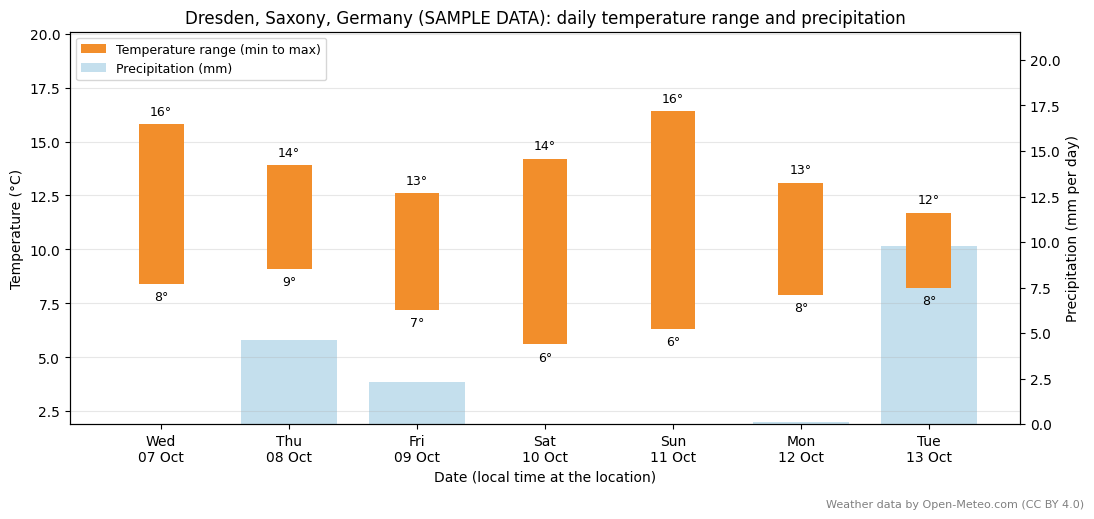

In [13]:
fig = plot_forecast(forecast, PLACE_LABEL)
fig.savefig("figures/weather_forecast.png", dpi=150)
plt.show()

---
# Part C — Robustness and second source

## C1. One wrapper for every request

Every call above went through `request_with_retries()` in `src/weather/http.py`. It:

- sets a **timeout** on every request;
- calls **`raise_for_status()`**;
- **retries** temporary failures (connection errors, timeouts, HTTP 5xx and 429) with **exponential backoff** (0.5 s, 1 s, 2 s, …) up to a **retry cap**;
- does **not** retry 4xx errors, because repeating a wrong request cannot fix it;
- raises one clear custom exception, **`WeatherAPIError`**, when it gives up.

## C2. Behaviour with deliberately broken inputs

In [14]:
# (1) Invalid city
show_zero_results("Zzzzzqqq-not-a-city")

(offline: using samples/geocoding_no_results.json)
geocode('Zzzzzqqq-not-a-city') returned []
LocationNotFoundError: No place called 'Zzzzzqqq-not-a-city' was found. Check the spelling.


In [15]:
# (2) Invalid latitude. First line of defence: our own validation, before any request is sent.
try:
    get_forecast(123.0, 13.7, 3)
except ValueError as err:
    print("Our validation  -> ValueError:", err)

# Second line of defence: if validation is bypassed, the API answers HTTP 400 and the wrapper reports its reason.
class SimulatedResponse:
    "A stand-in for requests.Response, used to replay a saved error body without the network."
    def __init__(self, status_code, payload):
        self.status_code, self._payload, self.text = status_code, payload, json.dumps(payload)
    def json(self):
        return self._payload
    def raise_for_status(self):
        if self.status_code >= 400:
            raise requests.HTTPError(f"{self.status_code} Client Error")

class ScriptedSession:
    "Returns or raises a fixed list of outcomes, one per request, and counts the calls."
    def __init__(self, *outcomes):
        self.outcomes, self.calls = list(outcomes), 0
    def get(self, url, **kwargs):
        self.calls += 1
        outcome = self.outcomes.pop(0)
        if isinstance(outcome, Exception):
            raise outcome
        return outcome

try:
    get_forecast(123.0, 13.7, 3, validate=False, **REQUEST_OPTIONS)
    print("Unexpected: the API accepted latitude 123")
except WeatherAPIError as err:
    if err.status == 400:
        print("Live API        -> WeatherAPIError:", err, f"(attempts: {err.attempts}, not retried)")
    else:
        session = ScriptedSession(SimulatedResponse(400, load_sample("forecast_error_latitude.json")))
        try:
            get_forecast(123.0, 13.7, 3, validate=False, session=session)
        except WeatherAPIError as simulated:
            print("Replayed sample -> WeatherAPIError:", simulated, f"(attempts: {simulated.attempts}, not retried)")

Our validation  -> ValueError: Latitude must be between -90 and 90, got 123.0.


Replayed sample -> WeatherAPIError: HTTP 400 from https://api.open-meteo.com/v1/forecast: Latitude must be in range of -90 to 90°. Given: 123.0. (attempts: 1, not retried)


In [16]:
# (3) No network (simulated): every attempt raises ConnectionError. Watch the retries and the backoff.
waits = []
session = ScriptedSession(*[requests.ConnectionError("simulated: network cable unplugged")] * 4)
try:
    fetch_json(GEOCODING_URL, {"name": "Dresden"}, session=session, max_retries=3, backoff=0.5, sleep=waits.append)
except WeatherAPIError as err:
    print("WeatherAPIError:", err)
    print(f"Requests made: {session.calls} | waits between them (s): {waits} | total wait would be {sum(waits)} s")

# ...and a temporary fault that recovers: two HTTP 503 replies, then success.
waits = []
session = ScriptedSession(SimulatedResponse(503, {}), SimulatedResponse(503, {}), SimulatedResponse(200, {"results": []}))
data = fetch_json(GEOCODING_URL, {"name": "Dresden"}, session=session, sleep=waits.append)
print(f"\nRecovered after {session.calls} attempts (waits: {waits}) ->", data)

WeatherAPIError: Giving up on https://geocoding-api.open-meteo.com/v1/search after 4 attempt(s): connection failed (ConnectionError).
Requests made: 4 | waits between them (s): [0.5, 1.0, 2.0] | total wait would be 3.5 s

Recovered after 3 attempts (waits: [0.5, 1.0]) -> {'results': []}


In [17]:
# (4) A tiny timeout: 1 millisecond is not enough for any real server to answer.
started = time.perf_counter()
try:
    geocode("Dresden", email=CONTACT_EMAIL, timeout=0.001, max_retries=2, backoff=0.2)
    print("Unexpected: a reply arrived within 1 ms")
except WeatherAPIError as err:
    print("WeatherAPIError:", err)
    print(f"Gave up after {err.attempts} attempts in {time.perf_counter() - started:.1f} s; the notebook carried on.")

WeatherAPIError: Giving up on https://geocoding-api.open-meteo.com/v1/search after 3 attempt(s): timed out after 0.001 s.
Gave up after 3 attempts in 0.6 s; the notebook carried on.


In all four cases the program fails **loudly and specifically**: a `ValueError` for bad arguments, `LocationNotFoundError` for an unknown place, and `WeatherAPIError` (with the number of attempts and the last status) for network and server problems. Nothing crashes with a raw traceback, and nothing returns made-up data.

## C3. Second source: MET Norway Locationforecast 2.0

MET Norway's terms of service require a **User-Agent with real contact details** (requests without one get `403 Forbidden`) and coordinates with **at most 4 decimals**. `get_forecast_met_no()` enforces both and refuses to call the API while the email is still the placeholder.

MET Norway returns **hourly steps in UTC** (6-hourly further ahead), in **m/s** for wind. `parse_met_no_daily()` converts times to the location's timezone, wind to km/h, and aggregates to the same daily columns as Open-Meteo so the two can be compared.

In [18]:
def met_no_live() -> dict:
    return get_forecast_met_no(place.latitude, place.longitude, CONTACT_EMAIL, **REQUEST_OPTIONS)

try:
    met_json = met_no_live()
    MODE["C3 MET Norway"] = "live"
except WeatherError as err:
    if not USE_SAMPLES_IF_OFFLINE:
        raise
    MODE["C3 MET Norway"] = "sample"
    print(f"*** {type(err).__name__}: {err}")
    print("*** Using saved sample samples/met_no_dresden.json (illustrative values). NOT live data.\n")
    met_json = load_sample("met_no_dresden.json")

met_timezone = place.timezone if MODE["C3 MET Norway"] == "live" else "Europe/Berlin"
met_daily = parse_met_no_daily(met_json, met_timezone)
met_daily

*** ConfigError: This API requires a real contact email in the User-Agent. Set CONTACT_EMAIL in the configuration cell (or the WEATHER_CONTACT_EMAIL environment variable) to your own university email.
*** Using saved sample samples/met_no_dresden.json (illustrative values). NOT live data.



,Max temp (°C),Min temp (°C),Precipitation (mm),Max wind (km/h),Steps
Date,,,,,
2026-10-07,15.9,10.4,0.0,20.5,12
2026-10-08,13.8,9.1,4.7,22.3,24
2026-10-09,12.6,7.1,2.9,25.2,21
2026-10-10,13.9,5.6,0.0,11.5,4
2026-10-11,16.2,6.6,0.0,12.2,4
2026-10-12,13.2,7.6,0.0,12.6,4
2026-10-13,11.6,8.4,13.7,27.0,4
2026-10-14,9.4,6.8,0.0,18.4,2


In [19]:
BOTH_LIVE = MODE["B2 forecast"] == "live" and MODE["C3 MET Norway"] == "live"
if not BOTH_LIVE:
    print("*** At least one source below is SAVED SAMPLE data, so the differences are illustrative, not findings.\n")
comparison = compare_sources(forecast, met_daily)
diff_cols = [c for c in comparison.columns if c.endswith("diff")]
display(comparison[diff_cols].rename(columns=lambda c: c.replace(" diff", ": Open-Meteo − MET Norway")))
print("Mean absolute difference:")
print(comparison[diff_cols].abs().mean().round(2).rename(lambda c: c.replace(" diff", "")).to_string())

*** At least one source below is SAVED SAMPLE data, so the differences are illustrative, not findings.



,Max temp (°C): Open-Meteo − MET Norway,Min temp (°C): Open-Meteo − MET Norway,Precipitation (mm): Open-Meteo − MET Norway,Max wind (km/h): Open-Meteo − MET Norway
Date,,,,
2026-10-07,-0.1,-2.0,0.0,-6.2
2026-10-08,0.1,0.0,-0.1,-0.6
2026-10-09,0.0,0.1,-0.6,-0.7
2026-10-10,0.3,0.0,0.0,1.3
2026-10-11,0.2,-0.3,0.0,-2.6
2026-10-12,-0.1,0.3,0.1,-4.5
2026-10-13,0.1,-0.2,-3.9,0.4


Mean absolute difference:
Max temp (°C)         0.13
Min temp (°C)         0.41
Precipitation (mm)    0.67
Max wind (km/h)       2.33


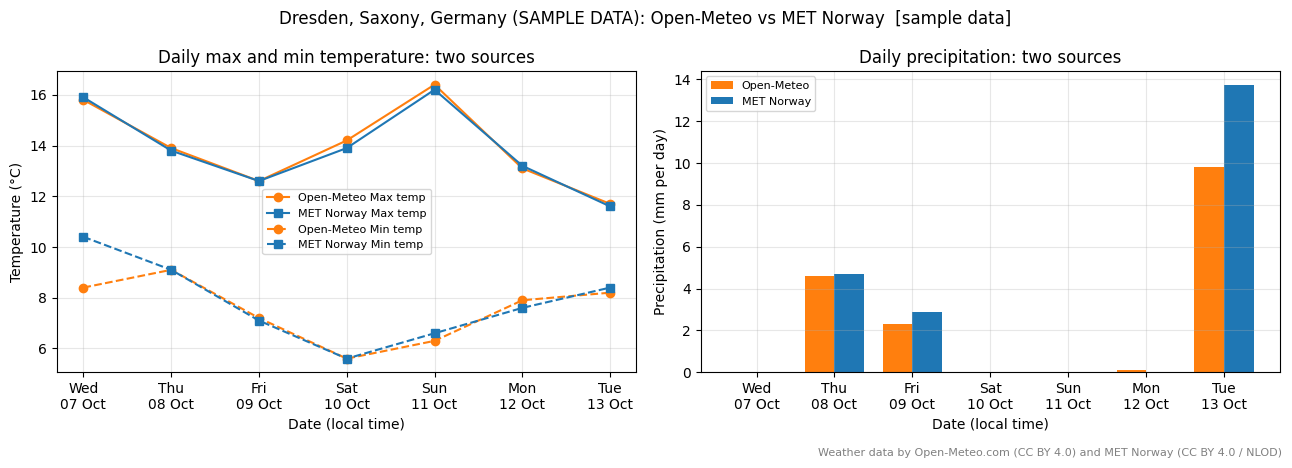

In [20]:
common = comparison.index
labels = [d.strftime("%a\n%d %b") for d in common]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for col, style in [(COL_TMAX, "-"), (COL_TMIN, "--")]:
    axes[0].plot(labels, forecast.loc[common, col], style, marker="o", color="tab:orange", label=f"Open-Meteo {col[:8]}")
    axes[0].plot(labels, met_daily.loc[common, col], style, marker="s", color="tab:blue", label=f"MET Norway {col[:8]}")
axes[0].set(title="Daily max and min temperature: two sources", xlabel="Date (local time)", ylabel="Temperature (°C)")
width = 0.38
x = range(len(common))
axes[1].bar([i - width / 2 for i in x], forecast.loc[common, COL_RAIN], width, color="tab:orange", label="Open-Meteo")
axes[1].bar([i + width / 2 for i in x], met_daily.loc[common, COL_RAIN], width, color="tab:blue", label="MET Norway")
axes[1].set_xticks(list(x), labels)
axes[1].set(title="Daily precipitation: two sources", xlabel="Date (local time)", ylabel="Precipitation (mm per day)")
for ax in axes:
    ax.legend(fontsize=8); ax.grid(alpha=0.3)
fig.suptitle(f"{PLACE_LABEL}: Open-Meteo vs MET Norway" + ("" if BOTH_LIVE else "  [sample data]"))
fig.text(0.99, 0.01, "Weather data by Open-Meteo.com (CC BY 4.0) and MET Norway (CC BY 4.0 / NLOD)", ha="right", fontsize=8, color="grey")
fig.tight_layout(rect=(0, 0.03, 1, 1)); fig.savefig("figures/weather_two_sources.png", dpi=150); plt.show()

**Reading the comparison.** Two forecasts for the same place rarely agree exactly, for reasons that have nothing to do with errors in the code: the services run different weather models on different grids, a "day" from MET Norway is built here from hourly instants (so it can miss a peak between the hours, and the first and last days are incomplete: see the `Steps` column), and beyond about two days MET Norway only gives 6-hourly steps. Temperatures normally agree to within a degree or two; precipitation and wind differ more. A second source is therefore best used as a **cross-check and a fallback**, not as a second opinion to average blindly.

## Saving today's raw responses (only when the data are live)

In [21]:
saved = []
for step, payload, filename in [("B2 forecast", forecast_json, "captured_forecast.json"),
                                ("C3 MET Norway", met_json, "captured_met_no.json"),
                                ("A2 requests geocoding", raw_requests, "captured_geocoding.json")]:
    if MODE.get(step) == "live":
        (SAMPLES / filename).write_text(json.dumps(payload, indent=1, ensure_ascii=False), encoding="utf-8")
        saved.append(filename)
print("Saved:", saved if saved else "nothing (no live data in this run)")
print("\nData mode per step:")
for step, mode in MODE.items():
    print(f"  {step:24s} {mode}")

Saved: nothing (no live data in this run)

Data mode per step:
  A1 urllib geocoding      sample
  A2 requests geocoding    sample
  B1 geocode               sample
  B2 forecast              sample
  C3 MET Norway            sample


## Offline checks on the parsing functions

The brief asks for at least five `assert`-based or pytest checks that run offline on saved sample JSON. Five are shown inline; the full set is in `tests/test_weather_parsing.py` and `tests/test_weather_http.py`.

In [22]:
sample_places = parse_geocoding(load_sample("geocoding_dresden.json"))
sample_forecast = parse_open_meteo_daily(load_sample("forecast_dresden.json"))
sample_met = parse_met_no_daily(load_sample("met_no_dresden.json"), "Europe/Berlin")

assert sample_places[0].name == "Dresden" and sample_places[0].country == "Germany"            # 1 geocoding fields
assert parse_geocoding(load_sample("geocoding_no_results.json")) == []                           # 2 missing 'results' key
assert sample_forecast.shape == (7, 6) and (sample_forecast[COL_TMAX] >= sample_forecast[COL_TMIN]).all()   # 3 shape, sanity
assert sample_forecast["Weather"].iloc[1] == "Slight rain"                                       # 4 WMO code 61 decoded
assert sample_met.loc["2026-10-08", "Steps"] == 24 and str(sample_met.index[0].date()) == "2026-10-07"   # 5 local-day grouping
try:
    parse_open_meteo_daily(load_sample("forecast_error_latitude.json"))
    raise AssertionError("an error body must not parse as a forecast")
except ValueError:
    pass                                                                                         # 6 error body rejected
print("All inline checks passed.")

All inline checks passed.


In [23]:
import subprocess, sys
run = subprocess.run([sys.executable, "-m", "pytest", "-q", "--color=no", "-p", "no:cacheprovider",
                      "tests/test_weather_parsing.py", "tests/test_weather_http.py"], capture_output=True, text=True)
print(run.stdout[-400:] or run.stderr[-400:])

.................................                                        [100%]
33 passed in 0.53s



---
# Part D — Report

## D1. Data flow: from user input to displayed forecast

The program is a pipeline with five stages, shown in the diagram below.

1. **Input.** The user types a place name and a contact email into the configuration cell. Nothing else is entered by hand.
2. **Geocoding.** `geocode(name)` sends the name to the Open-Meteo Geocoding API and receives a list of candidate places as JSON. `parse_geocoding()` turns each one into a `Location` object. If the list is empty the program stops with `LocationNotFoundError`. If several places share the name, `choose_location()` lists them and one is selected.
3. **Forecast request.** `get_forecast(lat, lon, days)` validates the coordinates and sends them to the Open-Meteo Forecast API, asking for five daily variables and `timezone=auto`.
4. **Parsing.** `parse_open_meteo_daily()` converts the JSON arrays into a pandas DataFrame with one row per local day, clear column names with units, and the numeric WMO weather code translated into words.
5. **Display.** The DataFrame feeds a text summary, a formatted table and a chart, each labelled with its data source.

Every network call passes through one function, `request_with_retries()`, which adds the timeout, the status check, the retries and the custom exception. The second source, MET Norway, joins at stage 3 and is reshaped at stage 4 into the same columns so the two can be compared.

Two design choices keep this flow testable. First, **fetching and parsing are separate functions**: parsers take a Python dictionary and never touch the network, so they can be tested offline with saved JSON. Second, **the things that vary are parameters**: the HTTP session, the sleep function and the input function can all be replaced, which is how the notebook demonstrates "no network" without unplugging anything.

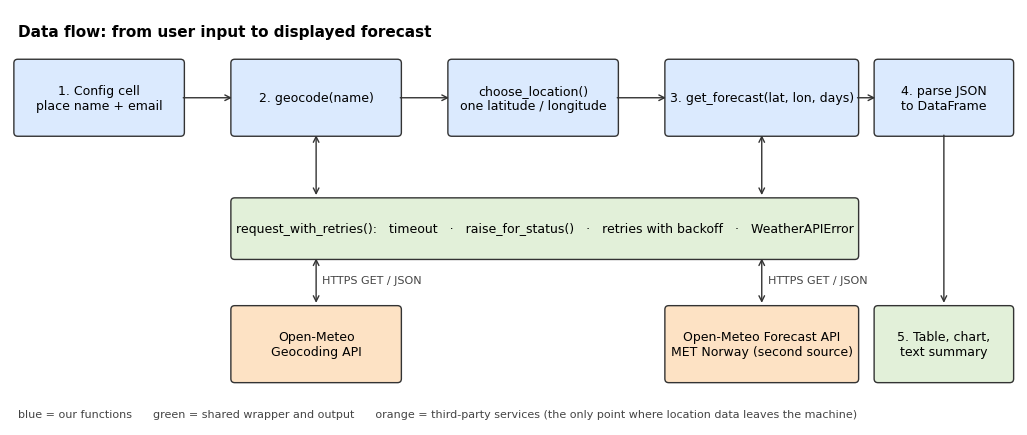

In [24]:
fig = draw_data_flow()
fig.savefig("figures/weather_data_flow.png", dpi=150)
plt.show()

## D2. Licensing and usage terms, and what they mean for a real product

**Open-Meteo.** The data are offered under the Creative Commons Attribution 4.0 licence (CC BY 4.0), so they may be reused and adapted provided the source is credited; this is why every table and chart here carries "Weather data by Open-Meteo.com". The free API needs no key but is for **non-commercial use only**, with limits of 600 calls a minute, 5,000 an hour, 10,000 a day and 300,000 a month. The terms count a site or app with subscriptions or advertising, or integration into a commercial product, as commercial use, which requires a paid plan and an API key. The service is provided "as is", with no warranty and no uptime guarantee. Place names come from GeoNames.

**MET Norway.** The data are also under CC BY 4.0 (together with the Norwegian Licence for Open Government Data), so credit and a link to the licence are required. The conditions are about behaviour rather than payment: every request must carry a **User-Agent identifying the application with contact details**, or it is refused with `403 Forbidden`; traffic is limited to 20 requests a second per application; clients must respect the `Expires` header and should use `If-Modified-Since` instead of re-downloading unchanged data; coordinates must have at most four decimals; and HTTPS is mandatory. There is explicitly no service-level agreement.

**What this means for a real product.** A classroom notebook sits comfortably inside both sets of terms. A product would not, in four ways. (1) A commercial app could not use Open-Meteo's free tier and would need a subscription, or would have to self-host the open-source service. (2) Attribution would have to be visible in the user interface, not buried in documentation. (3) Because neither free service guarantees availability, a product needs caching, a fallback source and a way to tell users the data are stale. (4) If many users' requests leave from one server, the limits apply to the whole application, so responses must be cached per location; MET Norway's caching rules make this a condition of use, not an optimisation. This project follows the same rules on a small scale: the email is read from an environment variable or a placeholder and never invented, MET Norway is not called without a real contact, coordinates are rounded to four decimals, and the notebook makes only a handful of requests per run.

## D3. Reliability issues met, and how the code handles them

**The network was not there.** The most instructive problem came first: on the network where the project was developed, a proxy refused every connection to the API hosts, so all requests failed before reaching a server. This shaped the design. All requests go through one wrapper that retries with exponential backoff and then raises `WeatherAPIError` saying how many attempts were made. Parsing is independent of fetching, so development and testing continued on saved JSON. The notebook can fall back to that saved JSON, labelling the output as sample data, so it still runs from top to bottom.

**Missing keys.** When nothing matches, the geocoder does not return an empty `results` list; it leaves the key out. Indexing `payload["results"]` would crash with `KeyError`. The parser uses `.get("results")` and returns an empty list, and the caller turns that into a clear `LocationNotFoundError`.

**Ambiguous names.** A search for "Dresden" returned the German city and two towns in the United States. Taking the first result silently would sometimes produce a correct-looking forecast for the wrong continent, so candidates are listed with region, country and population before one is chosen.

**Errors that should and should not be retried.** A timeout or an HTTP 503 may succeed on a second try; an HTTP 400 for latitude 123 never will. The wrapper retries only the first kind. Invalid coordinates are also rejected locally before any request, which saves traffic and gives a better message.

**Time zones and units.** MET Norway reports UTC timestamps, hourly at first and six-hourly later, with wind in metres per second. Grouping by UTC date would assign evening hours to the wrong day. The parser converts to the location's time zone, converts wind to km/h, and records how many time steps each day is built from, because the first and last days are incomplete.

**Unknown values.** A weather code that is not in the table is displayed as "Unknown (code n)" rather than raising an error or being dropped.

What the code does **not** handle: it does not cache responses between runs, does not honour `Expires` headers, and does not detect a response that is valid JSON but out of date.

## D4. Privacy implications of sending location queries to third parties

A place name or a pair of coordinates looks harmless, but each request also carries the sender's **IP address**, a **timestamp** and a **User-Agent**. Together these can show where a person is, where they plan to travel, or where they live, and a pattern of repeated queries is more revealing than any single one. Open-Meteo states that it logs IP addresses for technical reasons and deletes web-server logs after 90 days; that is a reasonable policy, but it is the operator's policy and outside our control. Both operators are outside Uganda, so a Ugandan product would be transferring this information abroad and would need to consider the Data Protection and Privacy Act, 2019.

In this notebook the exposure is small: the queries are typed city names, the only personal detail sent is the developer's own email in the User-Agent, and all traffic uses HTTPS. In a product using a phone's GPS position, the risks would be real, and four measures would reduce them. **Minimise precision:** weather does not change over a few metres, so coordinates can be rounded to two decimals (about one kilometre) before sending; MET Norway already forbids more than four. **Proxy and cache:** if the app's own server makes the request, the weather service sees the server's address, not the user's, and cached answers mean fewer queries leave at all. **Do not keep what is not needed:** the application should not log users' locations itself. **Be open:** the privacy notice should name the third-party services, and location should be optional, with typing a city name always available instead.